<a href="https://colab.research.google.com/github/kritikanpatil68/marketing-mix-model-meridian/blob/main/MMM_Meridian_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
   !pip install --upgrade google-meridian


In [ ]:
   from importlib.metadata import version
   import meridian
   print("Meridian is ready! Version:", version("google-meridian"))


In [4]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)          # fixed seed = same data every time

# ---------- 1. Basic setup ----------
n_geos, n_weeks = 20, 156                # 20 regions x 3 years of weekly data
dates = pd.date_range("2022-01-03", periods=n_weeks, freq="W-MON")
geos = [f"Region_{i+1:02d}" for i in range(n_geos)]
population = rng.uniform(0.5, 3.0, n_geos) * 1_000_000   # people per region

# ---------- 2. True media settings (the "answer key") ----------
channels = {
    # avg weekly spend per 1M people | adstock decay | half-saturation | max weekly effect (units per 1M people)
    "TV":           dict(spend=4000, decay=0.70, half=7000, beta=2600),
    "Paid_Search":  dict(spend=2000, decay=0.10, half=2000, beta=1600),
    "Social":       dict(spend=1500, decay=0.30, half=2000, beta=900),
    "Online_Video": dict(spend=1500, decay=0.50, half=2500, beta=900),
    "Display":      dict(spend=1000, decay=0.20, half=1500, beta=250),
}

def adstock(x, decay):
    """Carryover: this week's effect = this week's spend + decay x last week's effect."""
    out = np.zeros_like(x, dtype=float)
    for t in range(len(x)):
        out[t] = x[t] + (decay * out[t - 1] if t > 0 else 0)
    return out

def hill(x, half):
    """Diminishing returns: effect rises fast, then flattens. Reaches 50% at 'half'."""
    return x / (x + half)

week = np.arange(n_weeks)
seasonality = 1 + 0.15 * np.sin(2 * np.pi * week / 52) + 0.10 * np.isin(dates.month, [11, 12])
trend = 1 + 0.002 * week

rows, truth = [], {c: {"spend": 0.0, "revenue": 0.0} for c in channels}
for g, geo in enumerate(geos):
    pop_m = population[g] / 1_000_000
    region_size = pop_m                                   # bigger regions spend more

    # controls
    base_price = 4.99
    price = base_price * (1 + rng.normal(0, 0.04, n_weeks)) * (1 + 0.0004 * week)
    promo = (rng.random(n_weeks) < 0.20).astype(float) * rng.uniform(0.10, 0.25, n_weeks)  # discount depth
    shelf_price = price * (1 - promo)
    distribution = np.clip(75 + 8 * np.sin(2 * np.pi * (week + g) / 80) + rng.normal(0, 2, n_weeks), 50, 98)
    competitor_price = 4.79 * (1 + rng.normal(0, 0.05, n_weeks))

    # media spend: flighting (on/off bursts) + noise
    spend = {}
    for c, p in channels.items():
        on = (rng.random(n_weeks) < (0.9 if c != "TV" else 0.55)).astype(float)
        spend[c] = np.round(p["spend"] * region_size * on * rng.uniform(0.4, 1.6, n_weeks), 2)

    # baseline sales (units) driven by non-media factors
    base_units = 20000 * pop_m * seasonality * trend
    base_units *= (shelf_price / base_price) ** -1.6          # own price elasticity
    base_units *= (distribution / 75) ** 0.9                 # distribution effect
    base_units *= (competitor_price / 4.79) ** 0.5           # cross-price effect

    # media contribution (units)
    media_units = {}
    for c, p in channels.items():
        ad = adstock(spend[c] / region_size, p["decay"])     # per-capita spend
        media_units[c] = p["beta"] * pop_m * hill(ad, p["half"])

    units = base_units + sum(media_units.values())
    units = units * rng.normal(1, 0.04, n_weeks)             # random noise
    units = np.round(units)

    for c in channels:
        truth[c]["spend"] += spend[c].sum()
        truth[c]["revenue"] += (media_units[c] * shelf_price).sum()

    for t in range(n_weeks):
        r = dict(geo=geo, time=dates[t].date(), population=round(population[g]),
                 units_sold=units[t], avg_price=round(shelf_price[t], 2),
                 promo_discount=round(promo[t], 3), distribution_pct=round(distribution[t], 1),
                 competitor_price=round(competitor_price[t], 2))
        for c in channels:
            r[f"{c}_spend"] = spend[c][t]
        rows.append(r)

df = pd.DataFrame(rows)
true_roi = pd.DataFrame({c: {"true_ROI": v["revenue"] / v["spend"]} for c, v in truth.items()}).T.round(2)

df.to_csv("cpg_mmm_synthetic.csv", index=False)
true_roi.to_csv("true_roi_answer_key.csv")
print("Rows:", len(df), "| Regions:", df.geo.nunique(), "| Weeks:", df.time.nunique())
print(true_roi)
df.head()

Rows: 3120 | Regions: 20 | Weeks: 156
              true_ROI
TV                2.86
Paid_Search       2.06
Social            1.55
Online_Video      1.66
Display           0.56


,geo,time,population,units_sold,avg_price,promo_discount,distribution_pct,competitor_price,TV_spend,Paid_Search_spend,Social_spend,Online_Video_spend,Display_spend
0,Region_01,2022-01-03,2434890,47429.0,4.95,0.0,74.4,4.54,6854.91,4469.60,0.00,3401.86,3742.41
1,Region_01,2022-01-10,2434890,54962.0,4.86,0.0,76.0,4.21,0.00,5647.87,0.00,1775.61,1893.52
2,Region_01,2022-01-17,2434890,50783.0,5.24,0.0,77.5,5.18,0.00,7363.71,2302.09,4979.24,2011.70
3,Region_01,2022-01-24,2434890,65546.0,4.97,0.0,76.2,5.40,14611.46,0.00,2229.95,5375.01,0.00
4,Region_01,2022-01-31,2434890,61818.0,4.91,0.0,79.6,4.69,0.00,0.00,5019.72,1509.22,2189.93


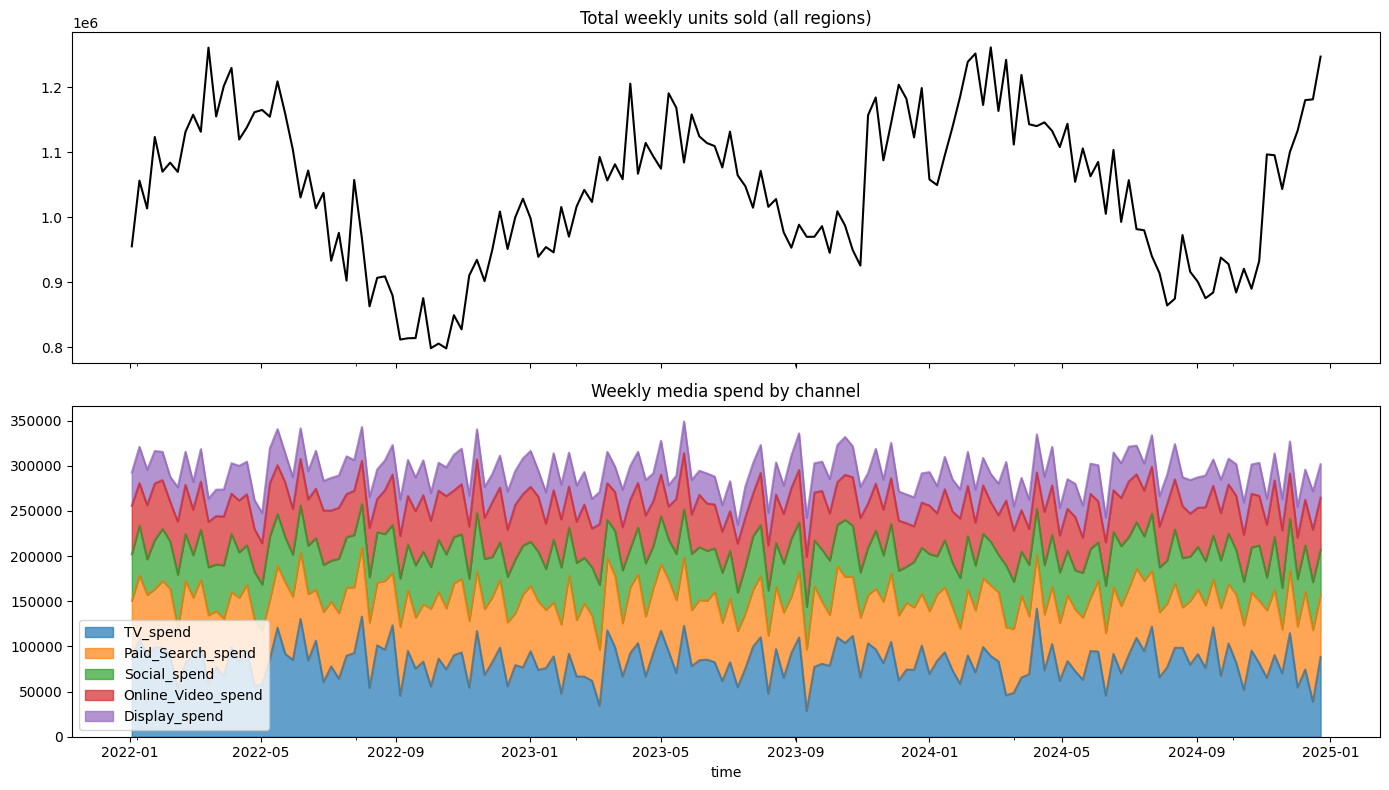

In [5]:
import matplotlib.pyplot as plt

channels = ["TV", "Paid_Search", "Social", "Online_Video", "Display"]
spend_cols = [f"{c}_spend" for c in channels]

# add up all 20 regions to get national weekly totals
weekly = df.groupby("time")[["units_sold"] + spend_cols].sum()

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax[0].plot(weekly.index, weekly["units_sold"], color="black")
ax[0].set_title("Total weekly units sold (all regions)")
weekly[spend_cols].plot.area(ax=ax[1], alpha=0.7)
ax[1].set_title("Weekly media spend by channel")
plt.tight_layout(); plt.show()

In [6]:
# share of total budget per channel
share = (df[spend_cols].sum() / df[spend_cols].sum().sum() * 100).round(1)
print("Share of media budget (%):")
print(share.sort_values(ascending=False))

# how each driver moves with sales
cols = ["units_sold", "avg_price", "promo_discount", "distribution_pct", "competitor_price"] + spend_cols
print("\nCorrelation with units sold:")
print(df[cols].corr()["units_sold"].drop("units_sold").round(2).sort_values())

Share of media budget (%):
TV_spend              28.3
Paid_Search_spend     23.9
Social_spend          18.0
Online_Video_spend    17.9
Display_spend         11.8
dtype: float64

Correlation with units sold:
avg_price            -0.34
competitor_price      0.05
distribution_pct      0.14
TV_spend              0.29
promo_discount        0.31
Online_Video_spend    0.47
Display_spend         0.48
Social_spend          0.51
Paid_Search_spend     0.53
Name: units_sold, dtype: float64


In [7]:
import statsmodels.formula.api as smf

avg_price = df["avg_price"].mean()
formula_naive = "units_sold ~ " + " + ".join(spend_cols)
naive = smf.ols(formula_naive, data=df).fit()

print("R-squared:", round(naive.rsquared, 3))
print("\nEstimated ROI (revenue per $1 spent):")
print((naive.params[spend_cols] * avg_price).round(2))

R-squared: 0.522

Estimated ROI (revenue per $1 spent):
TV_spend               2.76
Paid_Search_spend     14.26
Social_spend          16.15
Online_Video_spend    12.79
Display_spend         20.78
dtype: float64


In [9]:
import numpy as np
df["time"] = pd.to_datetime(df["time"])        # convert text/date to datetime
df["week_of_year"] = df["time"].dt.isocalendar().week.astype(int)

formula_ctrl = (formula_naive
    + " + avg_price + promo_discount + distribution_pct + competitor_price"
    + " + C(geo)"                                            # region effects
    + " + np.sin(2*np.pi*week_of_year/52) + np.cos(2*np.pi*week_of_year/52)")  # seasonality
ctrl = smf.ols(formula_ctrl, data=df).fit()

print("R-squared:", round(ctrl.rsquared, 3))
print("\nEstimated ROI (revenue per $1 spent):")
print((ctrl.params[spend_cols] * avg_price).round(2))

R-squared: 0.931

Estimated ROI (revenue per $1 spent):
TV_spend              0.34
Paid_Search_spend     1.31
Social_spend         -0.15
Online_Video_spend   -0.31
Display_spend        -0.63
dtype: float64


In [10]:
df = df.sort_values(["geo", "time"]).reset_index(drop=True)
df["pop_m"] = df["population"] / 1e6
df["units_pc"] = df["units_sold"] / df["pop_m"]                 # sales per 1M people
df["trend"] = df.groupby("geo").cumcount()                      # week number 0..155
df["holiday"] = df["time"].dt.month.isin([11, 12]).astype(int)  # Nov–Dec season

def adstock(x, decay):
    """Carryover: effect this week = spend this week + decay x last week's effect."""
    out = np.zeros(len(x))
    for t in range(len(x)):
        out[t] = x[t] + (decay * out[t-1] if t > 0 else 0)
    return out

def build_media(channel, decay, half_mult=1.0):
    """Adstock, then Hill saturation (diminishing returns)."""
    pc = df[f"{channel}_spend"] / df["pop_m"]
    ad = pc.groupby(df["geo"]).transform(lambda s: pd.Series(adstock(s.values, decay), index=s.index))
    half = ad[ad > 0].median() * half_mult        # spend level giving 50% of max effect
    df[f"{channel}_eff"] = ad / (ad + half)

controls = (" + avg_price + promo_discount + distribution_pct + competitor_price + C(geo)"
            " + trend + holiday + np.sin(2*np.pi*week_of_year/52) + np.cos(2*np.pi*week_of_year/52)")

def fit_and_roi():
    formula = "units_pc ~ " + " + ".join(f"{c}_eff" for c in channels) + controls
    m = smf.ols(formula, data=df).fit()
    roi = {c: (m.params[f"{c}_eff"] * df[f"{c}_eff"] * df["pop_m"] * df["avg_price"]).sum()
              / df[f"{c}_spend"].sum() for c in channels}
    return m, pd.Series(roi).round(2)

true_roi = pd.read_csv("true_roi_answer_key.csv", index_col=0)["true_ROI"]

for c in channels:
    build_media(c, decay=0.5)               # same guess for every channel
m1, roi1 = fit_and_roi()
print("R-squared:", round(m1.rsquared, 3))
print(pd.DataFrame({"model_ROI": roi1, "true_ROI": true_roi}))

R-squared: 0.931
              model_ROI  true_ROI
TV                 1.93      2.86
Paid_Search        3.20      2.06
Social             1.55      1.55
Online_Video       1.59      1.66
Display            0.51      0.56


In [11]:
best = {}
for c in channels:
    scores = {}
    for decay in [0.1, 0.3, 0.5, 0.7]:
        for half_mult in [0.5, 1, 2]:
            build_media(c, decay, half_mult)
            scores[(decay, half_mult)] = fit_and_roi()[0].rsquared
    best[c] = max(scores, key=scores.get)   # keep the best fit
    build_media(c, *best[c])

m2, roi2 = fit_and_roi()
print("Best (decay, half_mult) per channel:", best)
print("R-squared:", round(m2.rsquared, 3))
print(pd.DataFrame({"model_ROI": roi2, "true_ROI": true_roi}))

Best (decay, half_mult) per channel: {'TV': (0.7, 2), 'Paid_Search': (0.1, 1), 'Social': (0.7, 1), 'Online_Video': (0.3, 0.5), 'Display': (0.7, 2)}
R-squared: 0.932
              model_ROI  true_ROI
TV                 2.54      2.86
Paid_Search        1.87      2.06
Social             2.32      1.55
Online_Video       1.55      1.66
Display            0.69      0.56


In [12]:
from meridian.data import load
from meridian.model import model, spec
from meridian.analysis import analyzer

channels = ["TV", "Paid_Search", "Social", "Online_Video", "Display"]

# Meridian expects an "exposure" column per channel (normally impressions).
# Our data has spend only, so we use spend as the exposure measure.
data_in = pd.read_csv("cpg_mmm_synthetic.csv")
for c in channels:
    data_in[f"{c}_media"] = data_in[f"{c}_spend"]
data_in.to_csv("meridian_input.csv", index=False)

coords = load.CoordToColumns(
    time="time",
    geo="geo",
    kpi="units_sold",                 # what we explain
    revenue_per_kpi="avg_price",      # converts units into revenue for ROI
    population="population",          # scales regions fairly
    controls=["avg_price", "promo_discount", "distribution_pct", "competitor_price"],
    media=[f"{c}_media" for c in channels],
    media_spend=[f"{c}_spend" for c in channels],
)

loader = load.CsvDataLoader(
    csv_path="meridian_input.csv",
    coord_to_columns=coords,
    kpi_type="non_revenue",           # KPI is units, not dollars
    media_to_channel={f"{c}_media": c for c in channels},
    media_spend_to_channel={f"{c}_spend": c for c in channels},
)
mmm_data = loader.load()
print("Data loaded into Meridian")

Data loaded into Meridian


In [ ]:
mmm = model.Meridian(input_data=mmm_data, model_spec=spec.ModelSpec())

mmm.sample_prior(500)                 # what the model believes BEFORE seeing data
mmm.sample_posterior(                 # what it believes AFTER seeing data
    n_chains=4, n_adapt=500, n_burnin=500, n_keep=500, seed=1
)
print("Model fitted")

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

model.save_mmm(mmm, "/content/drive/MyDrive/mmm_fitted_model.pkl")
print("Model saved to Google Drive")

In [17]:
results = analyzer.Analyzer(mmm).summary_metrics(confidence_level=0.9)
roi = results["roi"].sel(distribution="posterior").to_dataframe()["roi"].unstack("metric")
roi = roi[["mean", "ci_lo", "ci_hi"]].round(2)
roi["true_ROI"] = true_roi
roi["regression_ROI"] = roi2
roi

/tmp/ipykernel_3258/2146659188.py:1: DeprecationWarning: The `meridian` argument is deprecated and will be removed in a future version. Use `model_context` instead.
  results = analyzer.Analyzer(mmm).summary_metrics(confidence_level=0.9)


metric,mean,ci_lo,ci_hi,true_ROI,regression_ROI
channel,,,,,
TV,2.20,1.79,2.65,2.86,2.54
Paid_Search,1.77,1.34,2.30,2.06,1.87
Social,1.41,0.41,2.87,1.55,2.32
Online_Video,1.33,0.53,2.40,1.66,1.55
Display,0.98,0.24,2.26,0.56,0.69
All Channels,1.65,1.34,2.06,NaN,NaN


In [18]:
diag = analyzer.Analyzer(mmm).rhat_summary()
diag[["param", "n_params", "avg_r_hat", "max_r_hat", "percent_bad_r_hat"]].round(3)

/tmp/ipykernel_3258/3798937348.py:1: DeprecationWarning: The `meridian` argument is deprecated and will be removed in a future version. Use `model_context` instead.
  diag = analyzer.Analyzer(mmm).rhat_summary()


,param,n_params,avg_r_hat,max_r_hat,percent_bad_r_hat
0,alpha_m,5.0,1.011,1.019,0.0
1,beta_gm,100.0,1.012,1.147,0.0
2,beta_m,5.0,1.020,1.075,0.0
3,ec_m,5.0,1.005,1.008,0.0
4,eta_m,5.0,1.020,1.045,0.0
5,gamma_c,4.0,1.001,1.001,0.0
6,gamma_gc,80.0,1.003,1.038,0.0
7,knot_values,156.0,1.546,1.618,1.0
8,mu_t,156.0,1.546,1.618,1.0
9,roi_m,5.0,1.045,1.067,0.0


In [19]:
visualizer = __import__("meridian.analysis.visualizer", fromlist=["visualizer"])
visualizer.ModelDiagnostics(mmm).predictive_accuracy_table()

,metric,geo_granularity,value
0,R_Squared,geo,0.984435
1,R_Squared,national,0.998655
2,MAPE,geo,0.035324
3,MAPE,national,0.002980
4,wMAPE,geo,0.035320
5,wMAPE,national,0.002949


In [20]:
visualizer.ModelFit(mmm).plot_model_fit()

alt.LayerChart(...)

In [21]:
decay = analyzer.Analyzer(mmm).adstock_decay(confidence_level=0.9)
decay[(decay["distribution"] == "posterior") & (decay["time_units"].isin([1.0, 2.0, 4.0]))][
    ["channel", "time_units", "mean"]].round(2)

/tmp/ipykernel_3258/2730496331.py:1: DeprecationWarning: The `meridian` argument is deprecated and will be removed in a future version. Use `model_context` instead.
  decay = analyzer.Analyzer(mmm).adstock_decay(confidence_level=0.9)


metric,channel,time_units,mean
10,Display,1.0,0.65
20,Display,2.0,0.48
40,Display,4.0,0.31
90,Online_Video,1.0,0.37
100,Online_Video,2.0,0.16
120,Online_Video,4.0,0.04
170,Paid_Search,1.0,0.10
180,Paid_Search,2.0,0.01
200,Paid_Search,4.0,0.00
250,Social,1.0,0.63


In [ ]:
mmm = model.Meridian(input_data=mmm_data, model_spec=spec.ModelSpec(knots=12))
mmm.sample_prior(500)
mmm.sample_posterior(n_chains=4, n_adapt=500, n_burnin=500, n_keep=500, seed=1)
model.save_mmm(mmm, "/content/drive/MyDrive/mmm_fitted_model_v2.pkl")
print("Model v2 fitted and saved")

In [23]:
a = analyzer.Analyzer(mmm)
print(a.rhat_summary()[["param", "max_r_hat", "percent_bad_r_hat"]].round(3))
print(visualizer.ModelDiagnostics(mmm).predictive_accuracy_table())

results = a.summary_metrics(confidence_level=0.9)
roi = results["roi"].sel(distribution="posterior").to_dataframe()["roi"].unstack("metric")
roi = roi[["mean", "ci_lo", "ci_hi"]].round(2)
roi["true_ROI"] = true_roi
roi

/tmp/ipykernel_3258/2716285592.py:1: DeprecationWarning: The `meridian` argument is deprecated and will be removed in a future version. Use `model_context` instead.
  a = analyzer.Analyzer(mmm)


          param  max_r_hat  percent_bad_r_hat
0       alpha_m      1.005                0.0
1       beta_gm      1.047                0.0
2        beta_m      1.009                0.0
3          ec_m      1.004                0.0
4         eta_m      1.024                0.0
5       gamma_c      1.005                0.0
6      gamma_gc      1.008                0.0
7   knot_values      1.094                0.0
8          mu_t      1.096                0.0
9         roi_m      1.007                0.0
10        sigma      0.999                0.0
11        tau_g      1.052                0.0
12         xi_c      1.021                0.0
      metric geo_granularity     value
0  R_Squared             geo  0.978296
1  R_Squared        national  0.924755
2       MAPE             geo  0.041840
3       MAPE        national  0.023525
4      wMAPE             geo  0.041942
5      wMAPE        national  0.022852


metric,mean,ci_lo,ci_hi,true_ROI
channel,,,,
TV,2.28,1.85,2.79,2.86
Paid_Search,1.76,1.27,2.37,2.06
Social,2.13,0.71,4.21,1.55
Online_Video,1.34,0.43,2.76,1.66
Display,0.80,0.21,1.87,0.56
All Channels,1.78,1.39,2.25,NaN


In [24]:
media_summary = visualizer.MediaSummary(mmm)
media_summary.summary_table()

/usr/local/lib/python3.13/dist-packages/meridian/analysis/visualizer.py:1809: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  .aggregate(lambda g: f'{g[0]} ({g[1]}, {g[2]})')


,channel,distribution,impressions,% impressions,spend,% spend,cpm,incremental outcome,% contribution,roi,effectiveness,mroi,cpik
0,TV,prior,"12,988,386",28%,"$12,988,386",28%,"$1,000","$22,525,137 ($4,226,904, $68,256,851)","2.5% (0.5%, 7.7%)","1.7 (0.3, 5.3)","1.73 (0.33, 5.26)","1.0 (0.2, 3.3)","$4.0 ($0.9, $15.2)"
1,TV,posterior,"12,988,386",28%,"$12,988,386",28%,"$1,000","$29,586,854 ($23,970,254, $36,244,524)","3.7% (3.0%, 4.5%)","2.3 (1.8, 2.8)","2.28 (1.85, 2.79)","1.6 (1.3, 1.9)","$2.2 ($1.8, $2.7)"
2,Paid_Search,prior,"10,963,773",24%,"$10,963,773",24%,"$1,000","$20,352,284 ($2,976,546, $64,183,335)","2.3% (0.3%, 7.2%)","1.9 (0.3, 5.9)","1.86 (0.27, 5.85)","0.9 (0.1, 3.0)","$4.2 ($0.8, $18.3)"
3,Paid_Search,posterior,"10,963,773",24%,"$10,963,773",24%,"$1,000","$19,276,625 ($13,941,294, $25,934,686)","2.4% (1.7%, 3.3%)","1.8 (1.3, 2.4)","1.76 (1.27, 2.37)","0.9 (0.5, 1.2)","$2.9 ($2.1, $3.9)"
4,Social,prior,"8,269,053",18%,"$8,269,053",18%,"$1,000","$14,876,347 ($2,392,770, $45,922,217)","1.7% (0.3%, 5.2%)","1.8 (0.3, 5.6)","1.80 (0.29, 5.55)","0.9 (0.1, 2.9)","$4.3 ($0.9, $17.1)"
5,Social,posterior,"8,269,053",18%,"$8,269,053",18%,"$1,000","$17,611,440 ($5,887,441, $34,792,172)","2.2% (0.7%, 4.4%)","2.1 (0.7, 4.2)","2.13 (0.71, 4.21)","1.0 (0.3, 1.8)","$2.5 ($1.2, $7.0)"
6,Online_Video,prior,"8,237,256",18%,"$8,237,256",18%,"$1,000","$14,306,181 ($2,561,395, $42,249,979)","1.6% (0.3%, 4.8%)","1.7 (0.3, 5.1)","1.74 (0.31, 5.13)","0.9 (0.1, 3.0)","$4.2 ($1.0, $16.0)"
7,Online_Video,posterior,"8,237,256",18%,"$8,237,256",18%,"$1,000","$11,003,123 ($3,559,078, $22,771,325)","1.4% (0.4%, 2.9%)","1.3 (0.4, 2.8)","1.34 (0.43, 2.76)","0.6 (0.2, 1.2)","$4.3 ($1.8, $11.5)"
8,Display,prior,"5,433,776",12%,"$5,433,776",12%,"$1,000","$10,083,162 ($1,463,797, $29,204,237)","1.1% (0.2%, 3.3%)","1.9 (0.3, 5.4)","1.86 (0.27, 5.37)","0.9 (0.1, 2.8)","$3.9 ($0.9, $18.4)"
9,Display,posterior,"5,433,776",12%,"$5,433,776",12%,"$1,000","$4,351,243 ($1,166,080, $10,172,606)","0.5% (0.1%, 1.3%)","0.8 (0.2, 1.9)","0.80 (0.21, 1.87)","0.4 (0.1, 0.8)","$7.5 ($2.6, $23.1)"


In [25]:
media_summary.plot_roi_vs_mroi()

alt.Chart(...)

In [26]:
visualizer.MediaEffects(mmm).plot_response_curves()

alt.FacetChart(...)

In [27]:
from meridian.analysis import optimizer

opt = optimizer.BudgetOptimizer(mmm).optimize(
    spend_constraint_lower=0.3,     # a channel can drop by at most 30%
    spend_constraint_upper=0.3,     # a channel can grow by at most 30%
)

before, after = opt.nonoptimized_data, opt.optimized_data
plan = pd.DataFrame({
    "current_spend": before.spend.values,
    "optimal_spend": after.spend.values,
}, index=before.channel.values).round(0)
plan["change_%"] = ((plan["optimal_spend"] / plan["current_spend"] - 1) * 100).round(1)

rev_before = before.attrs["total_incremental_outcome"]
rev_after = after.attrs["total_incremental_outcome"]
print(f"Total budget (unchanged): ${before.attrs['budget']:,.0f}")
print(f"Media-driven revenue: ${rev_before:,.0f} -> ${rev_after:,.0f} "
      f"(+{(rev_after / rev_before - 1) * 100:.1f}%)")
plan

Total budget (unchanged): $45,890,000
Media-driven revenue: $81,829,807 -> $85,306,817 (+4.2%)


,current_spend,optimal_spend,change_%
TV,12990000.0,16890000.0,30.0
Paid_Search,10960000.0,10070000.0,-8.1
Social,8270000.0,9360000.0,13.2
Online_Video,8240000.0,5770000.0,-30.0
Display,5430000.0,3800000.0,-30.0


In [28]:
opt.plot_spend_delta()

alt.LayerChart(...)